In [2]:
import warnings
warnings.simplefilter("ignore")


from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


In [3]:
df_pulito= pd.read_parquet('df_pulito.parquet')
df_unlearn=df_pulito.drop(['risultati'], axis=1).copy()

standard_scaler = StandardScaler().set_output(transform="pandas")

y_da_binarizzare= np.array(df_unlearn['sii'])
y_pulito = np.where(y_da_binarizzare >= 2.0, 1, 0)

X_pulito = df_unlearn.drop(columns=['id','sii','PCIAT-PCIAT_Total']).copy()

'''X_pulito_s = pd.DataFrame(
    standard_scaler.fit_transform(X_pulito), 
    columns=X_pulito.columns, 
    index=X_pulito.index
)'''

X_trainp, X_testp, y_trainp, y_testp = train_test_split(X_pulito, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

#dati standardizzati, servivano solo per tomek
#X_trainp_s, X_testp_s, y_trainp_s, y_testp_s = train_test_split(X_pulito_s, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

In [4]:
print(pd.Series(y_testp).value_counts())
print(pd.Series(y_trainp).value_counts())
print(pd.Series(y_pulito).value_counts())

'''0    87.899405
1    12.100595
dtype: float64'''
# iperparametri decisiontree

0    2169
1     299
Name: count, dtype: int64
0    5058
1     698
Name: count, dtype: int64
0    7227
1     997
Name: count, dtype: int64


'0    87.899405\n1    12.100595\ndtype: float64'

In [5]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier

# Definizione dello spazio degli iperparametri da esplorare
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 3, 5, 10],
    'class_weight': [None, 'balanced']
}

dt = DecisionTreeClassifier(random_state=42)

# Configuriamo la RandomizedSearch. Usiamo 'f1' come metrica visto lo sbilanciamento
random_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_dist,
    n_iter=20,          # Numero di combinazioni casuali da testare
    scoring='f1',       # Ottimizziamo per la classe minoritaria
    cv=5,               # 5-fold cross validation
    random_state=42,
    n_jobs=-1
)

print("Avvio RandomizedSearchCV per DecisionTreeClassifier...")
random_search.fit(X_trainp, y_trainp)

print("\nMigliori iperparametri trovati:")
print(random_search.best_params_)
print(f"Miglior F1-score (Cross-Validation): {random_search.best_score_:.4f}")

# Salviamo il modello ottimizzato
best_clf = random_search.best_estimator_


Avvio RandomizedSearchCV per DecisionTreeClassifier...

Migliori iperparametri trovati:
{'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 15, 'criterion': 'gini', 'class_weight': None}
Miglior F1-score (Cross-Validation): 0.4117


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

clf = DecisionTreeClassifier(min_samples_split= 2, min_samples_leaf=5, max_depth=10, criterion='gini')
clf.fit(X_trainp, y_trainp)

y_pred0 = clf.predict(X_testp)

print('Accuracy %s' % accuracy_score(y_testp, y_pred0))
print('F1-score %s' % f1_score(y_testp, y_pred0, average=None))
print(classification_report(y_testp, y_pred0))

importances = pd.Series(clf.feature_importances_, index=X_trainp.columns)
print(importances.sort_values(ascending=False).head(5))

#PCIAT-PCIAT_Total            0.942548
#praticamente viene usata solo questa per fare gli split quindi va levata? suppongo

'''Ho rimosso la variabile #PCIAT-PCIAT_Total perché introduceva Target Leakage. Essendo il target una discretizzazione 
del punteggio totale, lasciarla avrebbe reso il problema banale, portando il modello a imparare una semplice regola aritmetica 
anziché i pattern comportamentali sottostanti. Rimuovendola, ho forzato il modello a lavorare sui singoli item, aumentando il valore 
diagnostico e la capacità di generalizzazione su nuovi soggetti di cui potremmo avere solo risposte parziali.

Senza il totale, il Decision Tree inizierà a pesare i singoli comportamenti. 
Scoprirai, ad esempio, che la domanda 20 ("Quanto spesso preferisci stare su internet invece di uscire con gli amici?")
pesa molto più della domanda 4.
Interpretabilità: Potrai dire: "Il modello ha individuato che non è il punteggio totale a contare, ma questi 4 comportamenti specifici 
che, se presenti contemporaneamente, portano alla classe 3".'''

Accuracy 0.8914100486223663
F1-score [0.93947606 0.47244094]
              precision    recall  f1-score   support

           0       0.92      0.96      0.94      2169
           1       0.57      0.40      0.47       299

    accuracy                           0.89      2468
   macro avg       0.75      0.68      0.71      2468
weighted avg       0.88      0.89      0.88      2468

PCIAT-PCIAT_18    0.292591
BIA-BIA_LDM       0.074791
PCIAT-PCIAT_11    0.057137
PCIAT-PCIAT_20    0.051171
PCIAT-PCIAT_15    0.044019
dtype: float64


'Ho rimosso la variabile #PCIAT-PCIAT_Total perché introduceva Target Leakage. Essendo il target una discretizzazione \ndel punteggio totale, lasciarla avrebbe reso il problema banale, portando il modello a imparare una semplice regola aritmetica \nanziché i pattern comportamentali sottostanti. Rimuovendola, ho forzato il modello a lavorare sui singoli item, aumentando il valore \ndiagnostico e la capacità di generalizzazione su nuovi soggetti di cui potremmo avere solo risposte parziali.\n\nSenza il totale, il Decision Tree inizierà a pesare i singoli comportamenti. \nScoprirai, ad esempio, che la domanda 20 ("Quanto spesso preferisci stare su internet invece di uscire con gli amici?")\npesa molto più della domanda 4.\nInterpretabilità: Potrai dire: "Il modello ha individuato che non è il punteggio totale a contare, ma questi 4 comportamenti specifici \nche, se presenti contemporaneamente, portano alla classe 3".'

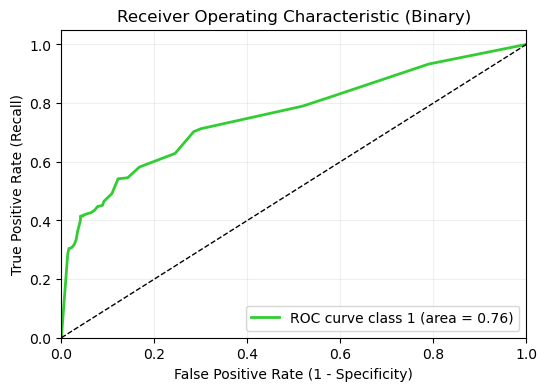

In [7]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

y_score0 = clf.predict_proba(X_testp)[:, 1]
fpr0, tpr0, thresholds0 = roc_curve(y_testp, y_score0)
roc_auc0 = auc(fpr0, tpr0)

plt.figure(figsize=(6, 4))
plt.plot(fpr0, tpr0, color='limegreen', lw=2, 
         label=f'ROC curve class 1 (area = {roc_auc0:.2f})')

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (Binary)')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

In [8]:
# storing class 1 ROC curve for successive comparisons
def plot_ROC_comparison(fpr, tpr):
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr0, tpr0, color='darkorange', lw=3, label='$AUC_0$ = %.3f' % (roc_auc0))
    plt.plot(fpr, tpr, color='green', lw=3, label='$AUC_1$ = %.3f' % (roc_auc))
    
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=16)
    plt.ylabel('True Positive Rate', fontsize=16)
    plt.title('ROC curve', fontsize=16)
    plt.legend(loc="lower right", fontsize=14, frameon=False)
    plt.tick_params(axis='both', which='major', labelsize=16)
    plt.show()

def plot_pca(X_pca, y_train):
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
    plt.show()

In [9]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN

## Scelte finali

1. Undersampling: CondensedNearestNeighbour
2. Oversampling: SMOTE o ADASYN
3. Balancing at the Algorithm Level: Class Weight

### Scelta Parametri: Condensed Nearest Neighbour (CNN)
**Logica della scelta:**
Il Condensed Nearest Neighbour è una tecnica di undersampling molto selettiva. I parametri principali da regolare sono `n_neighbors` (il numero di vicini da considerare per valutare se un punto è ridondante o meno) e `n_seeds_S` (il numero di campioni della classe maggioritaria con cui inizializzare il sottoinsieme). 
Considerando la dimensione ridotta della classe minoritaria (25 campioni), un `n_neighbors` elevato potrebbe portare alla rimozione di troppi campioni, degradando il confine decisionale. Pertanto, testeremo `n_neighbors` pari a 1 (di default, più fedele al confine) e 3 (per una maggiore robustezza al rumore).

--- Valutazione parametri per CNN ---

Test con n_neighbors = 1
Shape del dataset bilanciato: Counter({np.int64(0): 1356, np.int64(1): 698})
Accuracy: 0.8354943273905997
F1-score (per classe): [0.90406427 0.42329545]


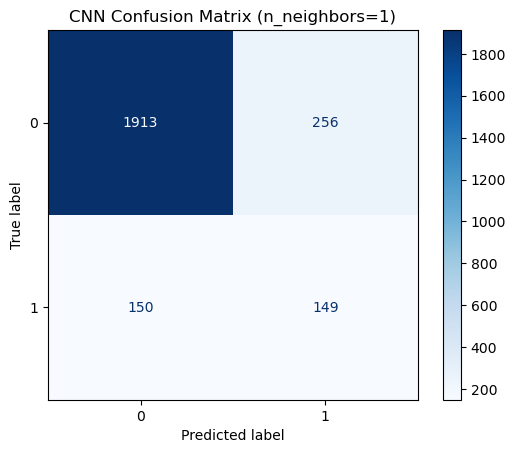


Test con n_neighbors = 3
Shape del dataset bilanciato: Counter({np.int64(0): 1214, np.int64(1): 698})
Accuracy: 0.7990275526742301
F1-score (per classe): [0.88030888 0.37373737]


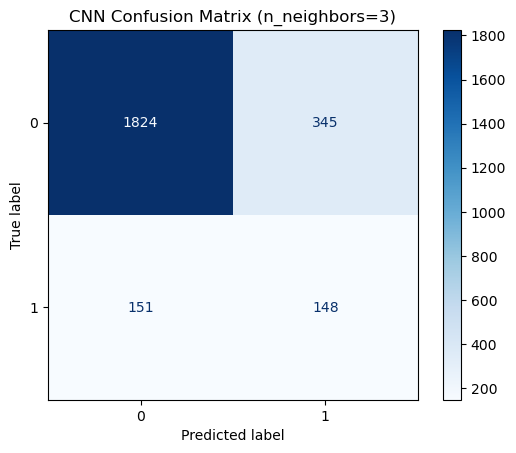

In [10]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
print("--- Valutazione parametri per CNN ---")
for n_neigh in [1, 3]:
    print(f"\nTest con n_neighbors = {n_neigh}")
    cnn = CondensedNearestNeighbour(random_state=222, n_neighbors=n_neigh, n_jobs=-1)
    X_res_cnn, y_res_cnn = cnn.fit_resample(X_trainp, y_trainp)
    print('Shape del dataset bilanciato:', Counter(y_res_cnn))
    
    # Fit del modello esistente
    clf.fit(X_res_cnn, y_res_cnn)
    y_pred_cnn = clf.predict(X_testp)
    
    print('Accuracy:', accuracy_score(y_testp, y_pred_cnn))
    print('F1-score (per classe):', f1_score(y_testp, y_pred_cnn, average=None))
    
    cm = confusion_matrix(y_testp, y_pred_cnn)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f'CNN Confusion Matrix (n_neighbors={n_neigh})')
    plt.show()


Resampled dataset shape Counter({np.int64(0): 1356, np.int64(1): 698})


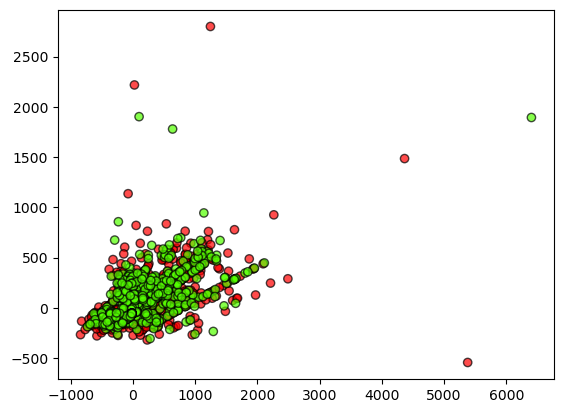

Accuracy 0.7799837925445705
F1-score [0.86582654 0.38920135]
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      2169
           1       0.29      0.58      0.39       299

    accuracy                           0.78      2468
   macro avg       0.61      0.69      0.63      2468
weighted avg       0.86      0.78      0.81      2468



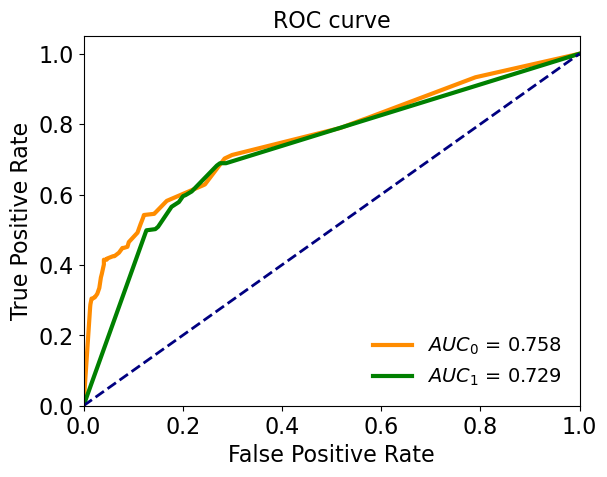

In [11]:
# --- CondensedNearestNeighbour ---

cnn = CondensedNearestNeighbour(random_state=222, n_jobs=10)
X_res, y_res = cnn.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))
pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

# fit
clf = DecisionTreeClassifier(min_samples_leaf=3, random_state=42)
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

### Scelta Parametri: ADASYN
**Logica della scelta:**
ADASYN genera campioni sintetici concentrandosi sulle regioni in cui la densità dei campioni di minoranza è più bassa rispetto a quelli di maggioranza (casi più difficili da imparare). Il parametro critico è `n_neighbors`, che stabilisce quanti vicini utilizzare per calcolare la densità e generare i nuovi campioni. 
Poiché abbiamo solo 25 campioni minoritari, un numero di vicini troppo alto rischierebbe di includere punti troppo lontani, generando campioni non rappresentativi. Testeremo `n_neighbors` in `[3, 5, 7]` per trovare il giusto compromesso tra varianza dei campioni generati e fedeltà alla distribuzione originaria.

--- Valutazione parametri per ADASYN ---

Test con n_neighbors = 3
Accuracy: 0.8545380875202593
F1-score (per classe): [0.91737629 0.39255499]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92      2169
           1       0.40      0.39      0.39       299

    accuracy                           0.85      2468
   macro avg       0.66      0.65      0.65      2468
weighted avg       0.85      0.85      0.85      2468



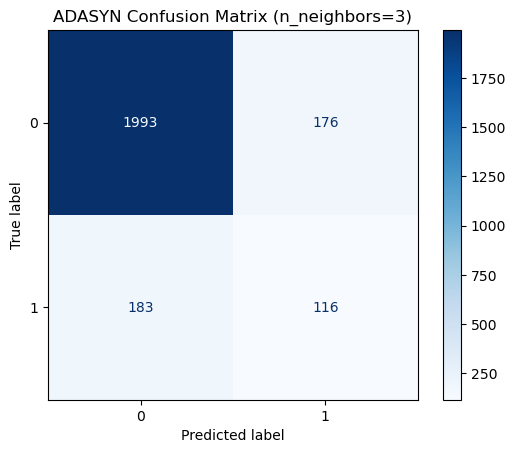


Test con n_neighbors = 5
Accuracy: 0.8399513776337115
F1-score (per classe): [0.90862827 0.35562806]

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.91      0.91      2169
           1       0.35      0.36      0.36       299

    accuracy                           0.84      2468
   macro avg       0.63      0.64      0.63      2468
weighted avg       0.84      0.84      0.84      2468



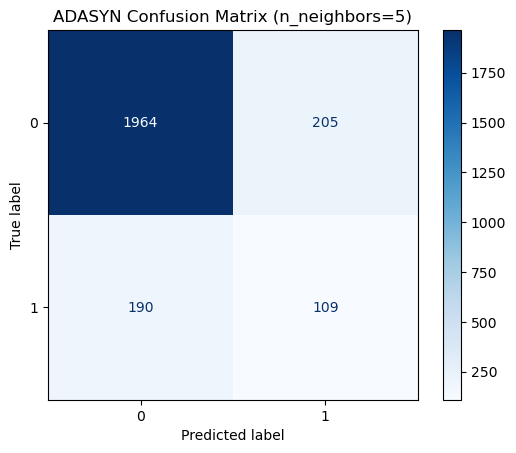


Test con n_neighbors = 7
Accuracy: 0.8614262560777958
F1-score (per classe): [0.92152363 0.4083045 ]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.93      0.92      2169
           1       0.42      0.39      0.41       299

    accuracy                           0.86      2468
   macro avg       0.67      0.66      0.66      2468
weighted avg       0.86      0.86      0.86      2468



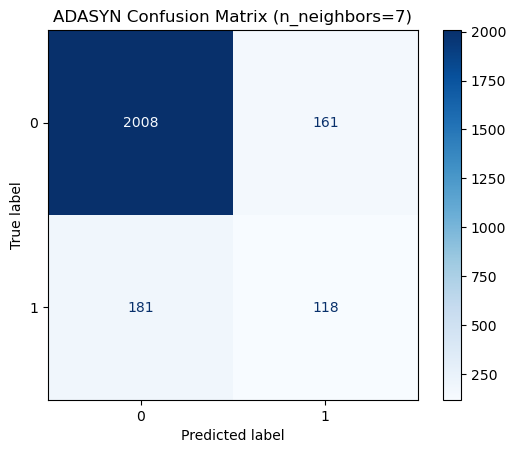

In [12]:
# --- Tuning ADASYN ---
from imblearn.over_sampling import ADASYN
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- Valutazione parametri per ADASYN ---")
for n_neigh in [3, 5, 7]:
    print(f"\nTest con n_neighbors = {n_neigh}")
    ada = ADASYN(random_state=42, n_neighbors=n_neigh)
    X_res_ada, y_res_ada = ada.fit_resample(X_trainp, y_trainp)
    
    # Inizializziamo il modello usando la struttura ottimizzata dalla Random Search
    clf = clone(best_clf)
    clf.fit(X_res_ada, y_res_ada)
    y_pred_ada = clf.predict(X_testp)
    
    print('Accuracy:', accuracy_score(y_testp, y_pred_ada))
    print('F1-score (per classe):', f1_score(y_testp, y_pred_ada, average=None))
    print('\nClassification Report:\n', classification_report(y_testp, y_pred_ada))
    
    cm = confusion_matrix(y_testp, y_pred_ada)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f'ADASYN Confusion Matrix (n_neighbors={n_neigh})')
    plt.show()


Resampled dataset shape Counter({np.int64(1): 5255, np.int64(0): 5058})


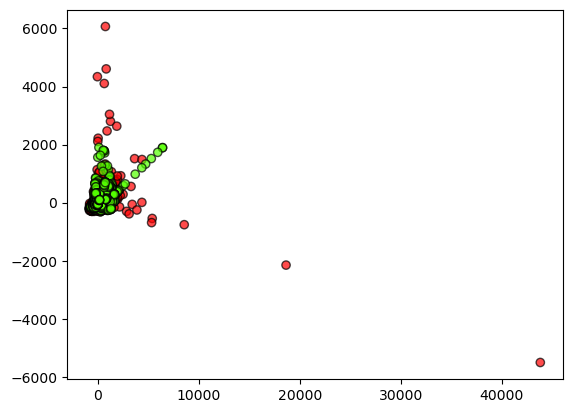

Accuracy 0.8399513776337115
F1-score [0.90862827 0.35562806]
              precision    recall  f1-score   support

           0       0.91      0.91      0.91      2169
           1       0.35      0.36      0.36       299

    accuracy                           0.84      2468
   macro avg       0.63      0.64      0.63      2468
weighted avg       0.84      0.84      0.84      2468



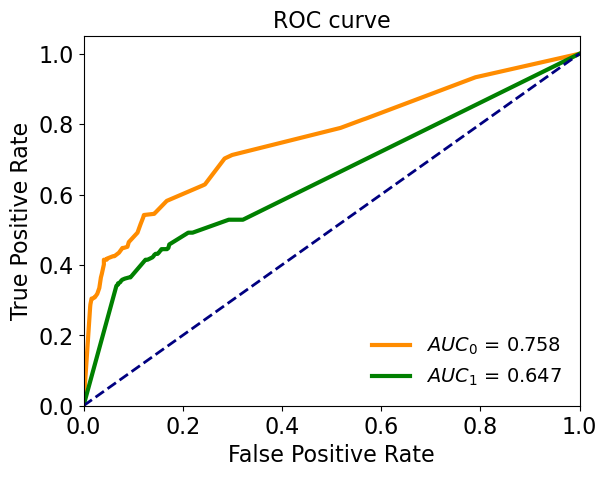

In [13]:
# --- ADASYN ---

ada = ADASYN(random_state=42)
X_res, y_res = ada.fit_resample(X_trainp, y_trainp)
#guidotti non mette i train ma X e y complete quindi boh controlla
print('Resampled dataset shape %s' % Counter(y_res))

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)



### Scelta Parametri: SMOTE
**Logica della scelta:**
A differenza di ADASYN, SMOTE interpola linearmente in modo uniforme lungo tutti i campioni minoritari. Anche qui il parametro chiave è `k_neighbors`. L'effetto di k_neighbors regola l'estensione dello spazio coperto dai campioni sintetici. 
Valuteremo `k_neighbors` in `[3, 5, 7]`. In contesti di forte sbilanciamento e pochi campioni (25), un k basso (es. 3) crea campioni molto simili a quelli originali (minore rischio di overlapping con la classe maggioritaria), mentre un k più alto esplora un volume maggiore.

--- Valutazione parametri per SMOTE ---

Test con k_neighbors = 3
Accuracy: 0.8565640194489466
F1-score (per classe): [0.91847075 0.4040404 ]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92      2169
           1       0.41      0.40      0.40       299

    accuracy                           0.86      2468
   macro avg       0.66      0.66      0.66      2468
weighted avg       0.86      0.86      0.86      2468



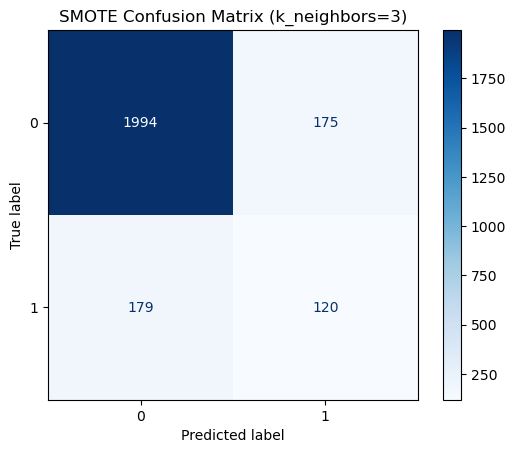


Test con k_neighbors = 5
Accuracy: 0.856969205834684
F1-score (per classe): [0.91871978 0.40472175]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92      2169
           1       0.41      0.40      0.40       299

    accuracy                           0.86      2468
   macro avg       0.66      0.66      0.66      2468
weighted avg       0.86      0.86      0.86      2468



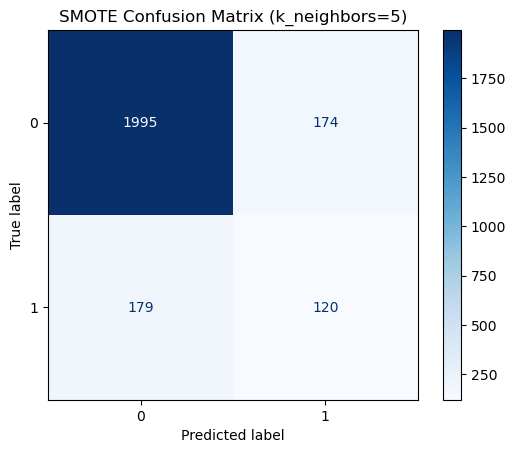


Test con k_neighbors = 7
Accuracy: 0.8610210696920584
F1-score (per classe): [0.92098595 0.42352941]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92      2169
           1       0.43      0.42      0.42       299

    accuracy                           0.86      2468
   macro avg       0.67      0.67      0.67      2468
weighted avg       0.86      0.86      0.86      2468



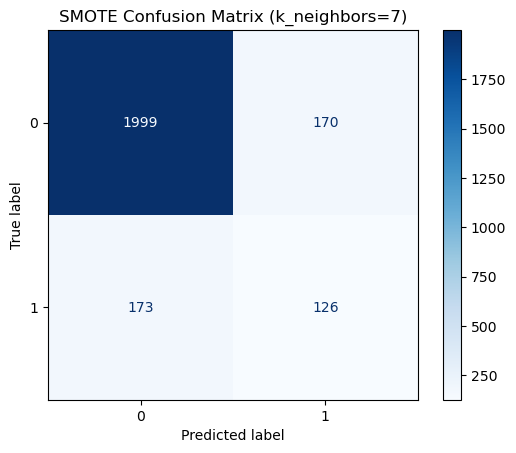

In [14]:
# --- Tuning SMOTE ---
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- Valutazione parametri per SMOTE ---")
for k_neigh in [3, 5, 7]:
    print(f"\nTest con k_neighbors = {k_neigh}")
    smote = SMOTE(random_state=42, k_neighbors=k_neigh)
    X_res_sm, y_res_sm = smote.fit_resample(X_trainp, y_trainp)
    
    # Inizializziamo il modello usando la struttura ottimizzata dalla Random Search
    clf = clone(best_clf)
    clf.fit(X_res_sm, y_res_sm)
    y_pred_sm = clf.predict(X_testp)
    
    print('Accuracy:', accuracy_score(y_testp, y_pred_sm))
    print('F1-score (per classe):', f1_score(y_testp, y_pred_sm, average=None))
    print('\nClassification Report:\n', classification_report(y_testp, y_pred_sm))
    
    cm = confusion_matrix(y_testp, y_pred_sm)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f'SMOTE Confusion Matrix (k_neighbors={k_neigh})')
    plt.show()


Resampled dataset shape Counter({np.int64(0): 5058, np.int64(1): 5058})


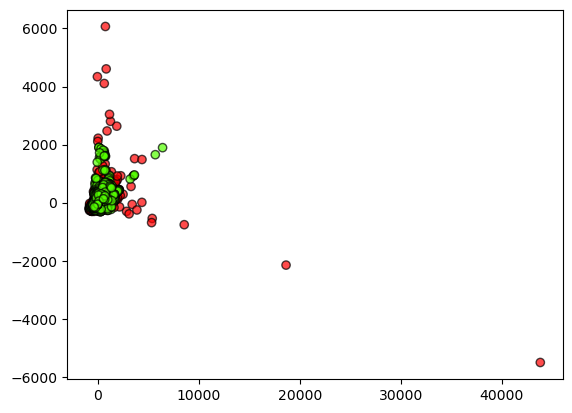

Accuracy 0.856969205834684
F1-score [0.91871978 0.40472175]
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      2169
           1       0.41      0.40      0.40       299

    accuracy                           0.86      2468
   macro avg       0.66      0.66      0.66      2468
weighted avg       0.86      0.86      0.86      2468



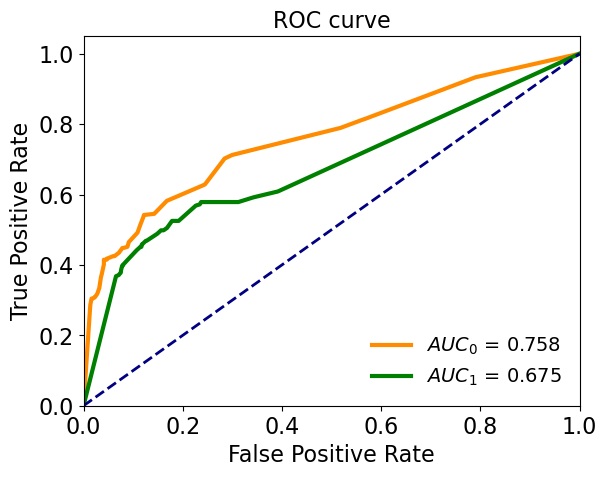

In [15]:
# --- SMOTE ---

sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
#plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)



### Scelta Parametri: Class Weight (Algorithmic Balancing)
**Logica della scelta:**
Il bilanciamento tramite pesi agisce direttamente sulla funzione di costo del Decision Tree. È un metodo che non altera i dati originali (niente undersampling o oversampling) ed è spesso più robusto e veloce. 
Il parametro chiave nel `DecisionTreeClassifier` è `class_weight`. 
- `class_weight='balanced'` calcola i pesi in modo inversamente proporzionale alle frequenze (es. assegnerà un peso circa 100 volte superiore alla classe minoritaria).
- Proveremo anche dei pesi custom: `{0: 1, 1: 50}` e `{0: 1, 1: 150}` per penalizzare in modo asimmetrico i falsi negativi.

In [16]:
'''# --- Tuning Class Weight ---
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- Valutazione parametri per Class Weight ---")
pesi_da_testare = [
    'balanced',
    {0: 1, 1: 50},
    {0: 1, 1: 100},
    {0: 1, 1: 150}
]

# Otteniamo i parametri ottimali trovati prima per riutilizzarli
if 'best_clf' in locals() or 'best_clf' in globals():
    base_params = best_clf.get_params().copy()
else:
    # Fallback nel caso non sia stata eseguita la Random Search
    base_params = {'min_samples_leaf': 3, 'random_state': 42}

for weight in pesi_da_testare:
    print(f"\nTest con class_weight = {weight}")
    
    # Iniettiamo il peso corrente nei parametri ottimali
    current_params = base_params.copy()
    current_params['class_weight'] = weight
    
    clf_cw = DecisionTreeClassifier(**current_params)
    
    # Fit sui dati ORIGINALI (non ricampionati)
    clf_cw.fit(X_trainp, y_trainp)
    y_pred_cw = clf_cw.predict(X_testp)
    
    print('Accuracy:', accuracy_score(y_testp, y_pred_cw))
    print('F1-score (per classe):', f1_score(y_testp, y_pred_cw, average=None))
    print('\nClassification Report:\n', classification_report(y_testp, y_pred_cw))
    
    cm = confusion_matrix(y_testp, y_pred_cw)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f'Class Weight Confusion Matrix (class_weight={weight})')
    plt.show()
'''

'# --- Tuning Class Weight ---\nfrom sklearn.tree import DecisionTreeClassifier\nfrom sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay\nimport matplotlib.pyplot as plt\n\nprint("--- Valutazione parametri per Class Weight ---")\npesi_da_testare = [\n    \'balanced\',\n    {0: 1, 1: 50},\n    {0: 1, 1: 100},\n    {0: 1, 1: 150}\n]\n\n# Otteniamo i parametri ottimali trovati prima per riutilizzarli\nif \'best_clf\' in locals() or \'best_clf\' in globals():\n    base_params = best_clf.get_params().copy()\nelse:\n    # Fallback nel caso non sia stata eseguita la Random Search\n    base_params = {\'min_samples_leaf\': 3, \'random_state\': 42}\n\nfor weight in pesi_da_testare:\n    print(f"\nTest con class_weight = {weight}")\n    \n    # Iniettiamo il peso corrente nei parametri ottimali\n    current_params = base_params.copy()\n    current_params[\'class_weight\'] = weight\n    \n    clf_cw = DecisionTreeClassifier(**current_pa

## Riassunto dei Risultati e Confronto Finale
In questa sezione alleniamo i modelli con i parametri ottimali emersi dal tuning e raccogliamo tutte le metriche, le curve ROC e le Matrici di Confusione in un'unica vista per facilitare il confronto.

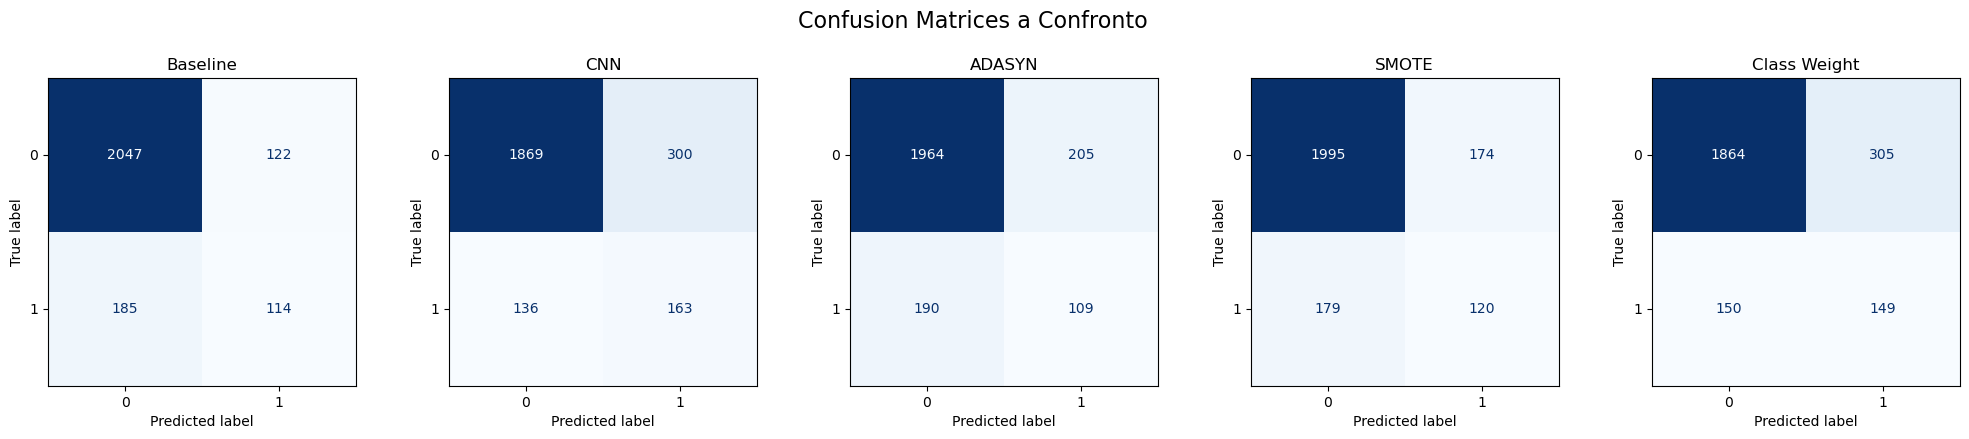

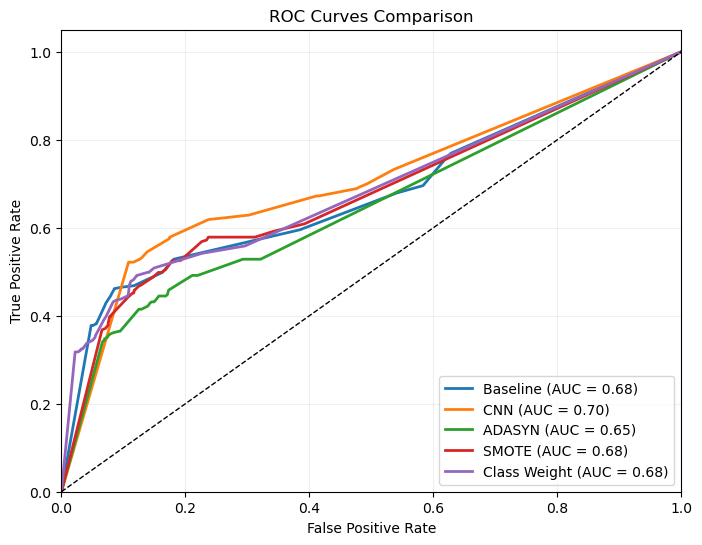

,Accuracy,Precision (Cl. 0),Recall (Cl. 0),F1-Score (Cl. 0),Precision (Cl. 1),Recall (Cl. 1),F1-Score (Cl. 1),ROC AUC
Baseline,0.876,0.917,0.944,0.930,0.483,0.381,0.426,0.676
CNN,0.823,0.932,0.862,0.896,0.352,0.545,0.428,0.702
ADASYN,0.840,0.912,0.905,0.909,0.347,0.365,0.356,0.647
SMOTE,0.857,0.918,0.920,0.919,0.408,0.401,0.405,0.675
Class Weight,0.816,0.926,0.859,0.891,0.328,0.498,0.396,0.684


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.over_sampling import ADASYN, SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

# Estrapoliamo i parametri dal miglior albero trovato dalla RandomizedSearch
best_params = best_clf.get_params()
best_params_cw = best_params.copy()
best_params_cw['class_weight'] = 'balanced'

# Dizionario per salvare i risultati
results = {}

# Definiamo i metodi con i parametri scelti dal tuning (es. valori di default/ottimali)
methods = {
    'Baseline': (None, clone(best_clf)),
    'CNN': (CondensedNearestNeighbour(random_state=42, n_neighbors=1, n_jobs=-1), clone(best_clf)),
    'ADASYN': (ADASYN(random_state=42, n_neighbors=5), clone(best_clf)),
    'SMOTE': (SMOTE(random_state=42, k_neighbors=5), clone(best_clf)),
    'Class Weight': (None, DecisionTreeClassifier(**best_params_cw))
}

fig_cm, axes = plt.subplots(1, 5, figsize=(25, 4))
fig_cm.suptitle('Confusion Matrices a Confronto', fontsize=16, y=1.05)

plt.figure(figsize=(8, 6)) # Per la curva ROC

for i, (name, (sampler, clf)) in enumerate(methods.items()):
    # Resampling
    if sampler:
        X_res, y_res = sampler.fit_resample(X_trainp, y_trainp)
    else:
        X_res, y_res = X_trainp, y_trainp
        
    # Fit
    clf.fit(X_res, y_res)
    
    # Predict
    y_pred = clf.predict(X_testp)
    y_score = clf.predict_proba(X_testp)[:, 1]
    
    # Metriche
    acc = accuracy_score(y_testp, y_pred)
    f1_min = f1_score(y_testp, y_pred, pos_label=1)
    f1_maj = f1_score(y_testp, y_pred, pos_label=0)
    prec_min = precision_score(y_testp, y_pred, pos_label=1, zero_division=0)
    rec_min = recall_score(y_testp, y_pred, pos_label=1, zero_division=0)
    prec_maj = precision_score(y_testp, y_pred, pos_label=0, zero_division=0)
    rec_maj = recall_score(y_testp, y_pred, pos_label=0, zero_division=0)
    
    # ROC
    fpr, tpr, _ = roc_curve(y_testp, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')
    
    # Confusion Matrix
    cm = confusion_matrix(y_testp, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name)
    
    # Salva in dict
    results[name] = {
        'Accuracy': round(acc, 3),
        'Precision (Cl. 0)': round(prec_maj, 3),
        'Recall (Cl. 0)': round(rec_maj, 3),
        'F1-Score (Cl. 0)': round(f1_maj, 3),
        'Precision (Cl. 1)': round(prec_min, 3),
        'Recall (Cl. 1)': round(rec_min, 3),
        'F1-Score (Cl. 1)': round(f1_min, 3),
        'ROC AUC': round(roc_auc, 3)
    }

# Mostra ROC
plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

# Mostra Confusion Matrices
plt.show()

# Tabella Riassuntiva
df_results = pd.DataFrame(results).T
display(df_results)


## Esperimento: Unbalanced Learning Estremo (96% vs 4%)
In questa sezione, simuliamo uno scenario di sbilanciamento molto più estremo (96% classe maggioritaria, 4% classe minoritaria) mantenendo comunque una binarizzazione sensata (`sii >= 2` come target). Riduciamo artificialmente i campioni della Classe 1 per forzare questa distribuzione, ed eseguiamo nuovamente il tuning dell'albero e le tecniche di resampling per vedere come si comportano in condizioni di forte scarsità di segnale.

Distribuzione del dataset estremo (96% vs 4%):
0    0.96
1    0.04
Name: proportion, dtype: float64
Conteggi reali:
0    7227
1     301
Name: count, dtype: int64

Avvio Tuning Decision Tree su dati estremi...
Migliori parametri trovati: {'min_samples_split': 20, 'min_samples_leaf': 5, 'max_depth': 15, 'criterion': 'gini'}

--- Baseline Decision Tree (Extreme Unbalanced) ---
F1-score (per classe): [0.97763578 0.27941176]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98      2169
           1       0.41      0.21      0.28        90

    accuracy                           0.96      2259
   macro avg       0.69      0.60      0.63      2259
weighted avg       0.95      0.96      0.95      2259



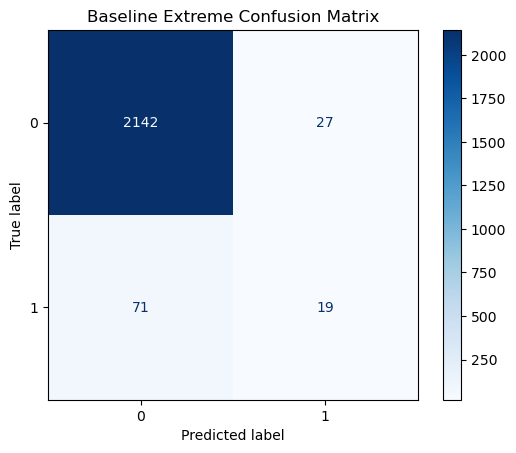

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.base import clone

# Ricarichiamo i dati per avere un ambiente pulito
df = pd.read_parquet('df_pulito.parquet')
df_unlearn = df.drop(['risultati'], axis=1).copy()

# 1. Binarizzazione (sii >= 2 diventa 1)
y_all = np.where(df_unlearn['sii'] >= 2.0, 1, 0)
X_all = df_unlearn.drop(columns=['id', 'sii', 'PCIAT-PCIAT_Total']).copy()

# Per ottenere 96% vs 4%, calcoliamo i campioni necessari.
# Classe 0 attuale: ~7234. Per avere il 96% di classe 0 e 4% di classe 1:
# Target Classe 1 = 7234 * (4 / 96) = 301.4 -> 301 campioni.

# Separiamo le classi
X_0 = X_all[y_all == 0]
y_0 = y_all[y_all == 0]

X_1 = X_all[y_all == 1]
y_1 = y_all[y_all == 1]

# Sottocampioniamo casualmente la Classe 1 a 301 campioni
np.random.seed(42)
idx_1_sample = np.random.choice(X_1.index, size=301, replace=False)
X_1_sampled = X_1.loc[idx_1_sample]
y_1_sampled = y_1[X_1.index.isin(idx_1_sample)]

# Ricombiniamo il dataset
X_ext = pd.concat([X_0, X_1_sampled])
y_ext = np.concatenate([y_0, y_1_sampled])

print("Distribuzione del dataset estremo (96% vs 4%):")
print(pd.Series(y_ext).value_counts(normalize=True).round(3))
print("Conteggi reali:")
print(pd.Series(y_ext).value_counts())

# Train/Test split
X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_ext, y_ext, test_size=0.3, random_state=100, stratify=y_ext
)

# 2. Tuning del DecisionTreeClassifier su questo nuovo dataset
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 3, 5, 10]
}

dt_ext = DecisionTreeClassifier(random_state=42)
random_search_ext = RandomizedSearchCV(
    estimator=dt_ext,
    param_distributions=param_dist,
    n_iter=20,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1
)

print("\nAvvio Tuning Decision Tree su dati estremi...")
random_search_ext.fit(X_train_ext, y_train_ext)
best_clf_ext = random_search_ext.best_estimator_

print("Migliori parametri trovati:", random_search_ext.best_params_)

# Valutazione Baseline
y_pred_base = best_clf_ext.predict(X_test_ext)
print('\n--- Baseline Decision Tree (Extreme Unbalanced) ---')
print('F1-score (per classe):', f1_score(y_test_ext, y_pred_base, average=None))
print('\nClassification Report:\n', classification_report(y_test_ext, y_pred_base, zero_division=0))

cm = confusion_matrix(y_test_ext, y_pred_base)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title('Baseline Extreme Confusion Matrix')
plt.show()


--- CNN (Extreme) ---
F1-score (per classe): [0.95996276 0.22522523]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.95      0.96      2169
           1       0.19      0.28      0.23        90

    accuracy                           0.92      2259
   macro avg       0.58      0.61      0.59      2259
weighted avg       0.94      0.92      0.93      2259



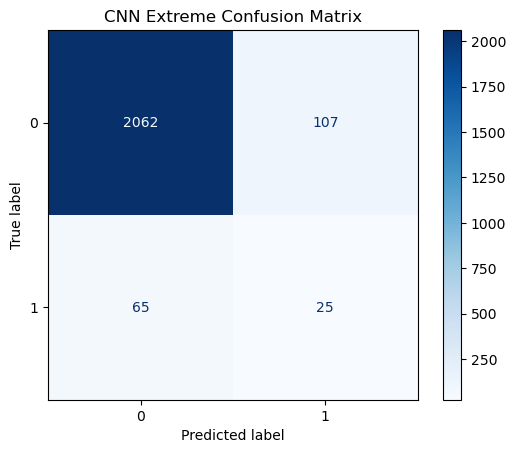

In [19]:
# --- CNN Extreme ---
from imblearn.under_sampling import CondensedNearestNeighbour
from sklearn.metrics import classification_report

print("--- CNN (Extreme) ---")
cnn_ext = CondensedNearestNeighbour(random_state=42, n_neighbors=1, n_jobs=-1)
X_res_cnn_ext, y_res_cnn_ext = cnn_ext.fit_resample(X_train_ext, y_train_ext)

clf_cnn_ext = clone(best_clf_ext)
clf_cnn_ext.fit(X_res_cnn_ext, y_res_cnn_ext)
y_pred_cnn_ext = clf_cnn_ext.predict(X_test_ext)

print('F1-score (per classe):', f1_score(y_test_ext, y_pred_cnn_ext, average=None))
print('\nClassification Report:\n', classification_report(y_test_ext, y_pred_cnn_ext, zero_division=0))
cm = confusion_matrix(y_test_ext, y_pred_cnn_ext)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title('CNN Extreme Confusion Matrix')
plt.show()


--- ADASYN (Extreme) ---
F1-score (per classe): [0.96448339 0.15384615]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.96      0.96      2169
           1       0.15      0.16      0.15        90

    accuracy                           0.93      2259
   macro avg       0.56      0.56      0.56      2259
weighted avg       0.93      0.93      0.93      2259



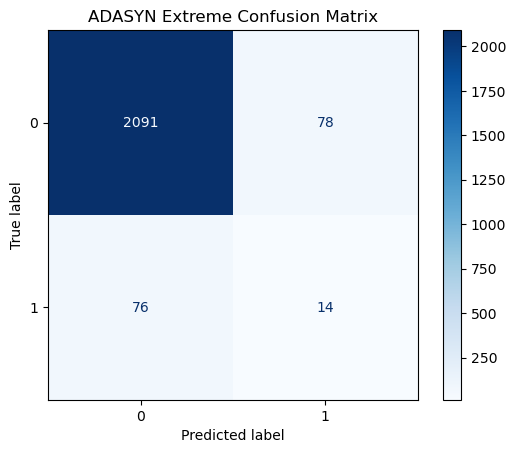

In [20]:
# --- ADASYN Extreme ---
from imblearn.over_sampling import ADASYN
from sklearn.metrics import classification_report

print("--- ADASYN (Extreme) ---")
ada_ext = ADASYN(random_state=42, n_neighbors=5)
X_res_ada_ext, y_res_ada_ext = ada_ext.fit_resample(X_train_ext, y_train_ext)

clf_ada_ext = clone(best_clf_ext)
clf_ada_ext.fit(X_res_ada_ext, y_res_ada_ext)
y_pred_ada_ext = clf_ada_ext.predict(X_test_ext)

print('F1-score (per classe):', f1_score(y_test_ext, y_pred_ada_ext, average=None))
print('\nClassification Report:\n', classification_report(y_test_ext, y_pred_ada_ext, zero_division=0))
cm = confusion_matrix(y_test_ext, y_pred_ada_ext)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title('ADASYN Extreme Confusion Matrix')
plt.show()


--- SMOTE (Extreme) ---
F1-score (per classe): [0.96511897 0.2010582 ]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.96      0.97      2169
           1       0.19      0.21      0.20        90

    accuracy                           0.93      2259
   macro avg       0.58      0.59      0.58      2259
weighted avg       0.94      0.93      0.93      2259



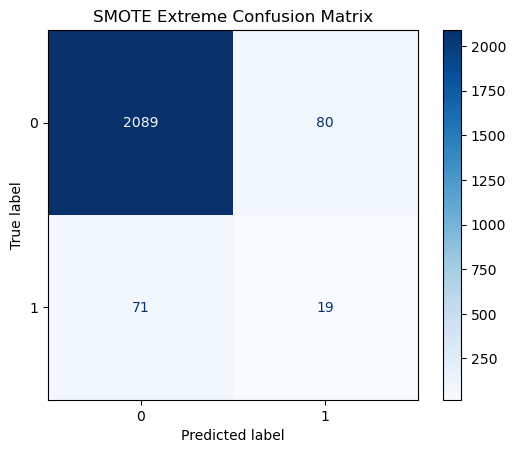

In [21]:
# --- SMOTE Extreme ---
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report

print("--- SMOTE (Extreme) ---")
smote_ext = SMOTE(random_state=42, k_neighbors=5)
X_res_sm_ext, y_res_sm_ext = smote_ext.fit_resample(X_train_ext, y_train_ext)

clf_sm_ext = clone(best_clf_ext)
clf_sm_ext.fit(X_res_sm_ext, y_res_sm_ext)
y_pred_sm_ext = clf_sm_ext.predict(X_test_ext)

print('F1-score (per classe):', f1_score(y_test_ext, y_pred_sm_ext, average=None))
print('\nClassification Report:\n', classification_report(y_test_ext, y_pred_sm_ext, zero_division=0))
cm = confusion_matrix(y_test_ext, y_pred_sm_ext)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title('SMOTE Extreme Confusion Matrix')
plt.show()
